# Encoding a regulatory network in ChiRho: CRISPR knockdown effects from (synthetic) scRNA-seq

**Purpose.** A small, reviewable proof-of-concept showing *how to put prior knowledge of a gene
regulatory network* — which genes regulate which (structure) and in which direction
(polarity: activating `+`, repressing `−`, or unknown `?`) — into a
[ChiRho](https://basisresearch.github.io/chirho/) causal model, and then use ChiRho's `do()`
to ask *"what happens to every gene if we knock down gene X with CRISPR?"*

**Starting point.** The ChiRho [SciPlex tutorial](https://basisresearch.github.io/chirho/sciplex.html)
fits an independent Poisson regression per gene, with latent confounders and a drug dose as the
treatment. Genes are only linked through shared latent factors — there is no network.

**What is new here.**

| SciPlex tutorial | This notebook |
|---|---|
| Drug dose → each gene independently | CRISPR guide → one target gene → effects propagate along the network |
| No regulatory network | Prior network: edges fixed by structure, weight signs fixed by polarity |
| Several cell lines, real data | One cell type, synthetic data with known ground truth |
| Hard, single-site treatment | **Soft** knockdown (CRISPRi): target is pushed down but stays regulated |
| — | Feedback loops, handled by assuming cells are at **steady state** |

**Outline.** (2) prior network → (3) synthetic data → (4) the ChiRho model → (5–6) fitting and
checks → (7) causal queries with `do()` incl. a knockdown never seen in training →
(8) soft vs hard knockdown → (9) what goes wrong if knockdown strength is assumed →
(10) limitations.

Every section ends with a small `assert` cell: these are the notebook's tests, so
"Restart & Run All" doubles as a check that the claims in the text hold.

In [1]:
import math

import chirho
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pyro
import pyro.distributions as dist
import torch
from chirho.counterfactual.handlers import MultiWorldCounterfactual
from chirho.indexed.ops import IndexSet, gather
from chirho.interventional.handlers import do
from matplotlib.lines import Line2D
from pyro.distributions import constraints
from pyro.infer import SVI, Predictive, Trace_ELBO
from pyro.infer.autoguide import AutoGuideList, AutoMultivariateNormal
from pyro.nn import PyroModule, PyroParam

pyro.set_rng_seed(0)
torch.manual_seed(0)
rng = np.random.default_rng(0)
torch.set_default_dtype(torch.float64)
# fixed categorical colour order for plots (assigned by entity, never cycled)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.edgecolor": INK2,
    }
)
print(f"pyro {pyro.__version__}, chirho {chirho.__version__}, torch {torch.__version__}")

pyro 1.9.2, chirho 0.3.0, torch 2.13.0


## 2. The prior regulatory network

We use a toy network of six genes, `A`–`F`. The prior knowledge is a list of edges
`(regulator, target, polarity)`:

* `A → B → C ⊣ A` is a **negative feedback loop** (A activates B, B activates C, C represses A).
* `A → D ⊣ E → F` is a downstream cascade.
* `B → E` is a known interaction whose **polarity is unknown** (`?`).

CRISPR guides target `A`, `D`, `E` (used for training) and `B` (**held out** — the model never sees
cells carrying this guide; we predict them).

**Encoding.** We turn the edge list into two `G × G` matrices indexed `[target, regulator]`
(row = the gene being regulated, column = its regulator):

* `mask[g, p] = 1` if `p → g` is in the prior network, else `0` — absent edges get weight exactly 0;
* `sign[g, p] = +1` (activating), `−1` (repressing), or `0` (unknown, or no edge).

| polarity | prior on the edge weight `W[g, p]` |
|---|---|
| `+` | `HalfNormal(σ_w)` — positive only |
| `−` | `−HalfNormal(σ_w)` — negative only |
| `?` | `Normal(0, σ_w)` — either sign, learned from data |
| no edge | fixed at `0` |

In [2]:
GENES = ["A", "B", "C", "D", "E", "F"]
EDGES = [  # (regulator, target, polarity)
    ("A", "B", "+"),
    ("B", "C", "+"),
    ("C", "A", "-"),
    ("A", "D", "+"),
    ("D", "E", "-"),
    ("B", "E", "?"),
    ("E", "F", "+"),
]
TRAIN_TARGETS = ["A", "D", "E"]
HELDOUT_TARGET = "B"
GUIDE_TARGETS = [*TRAIN_TARGETS, HELDOUT_TARGET]
G, K = len(GENES), len(GUIDE_TARGETS)
IDX = {g: k for k, g in enumerate(GENES)}
TARGET_IDX = torch.tensor([IDX[t] for t in GUIDE_TARGETS])

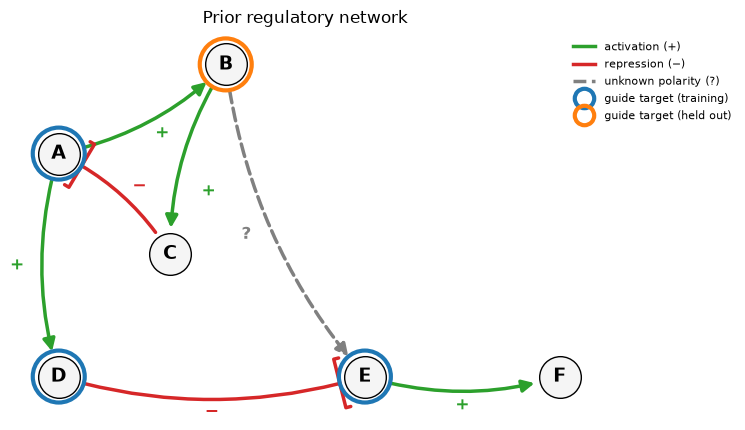

In [3]:
POLARITY = {"+": 1.0, "-": -1.0, "?": 0.0}
EDGE_STYLE = {  # polarity -> (colour, line style, arrow head)
    "+": ("tab:green", "solid", "-|>"),
    "-": ("tab:red", "solid", "-["),
    "?": ("grey", "dashed", "-|>"),
}


def prior_matrices(genes, edges):
    """Return (mask, sign), both G x G and indexed [target, regulator]."""
    idx = {g: k for k, g in enumerate(genes)}
    mask = torch.zeros(len(genes), len(genes))
    sign = torch.zeros(len(genes), len(genes))
    for parent, child, pol in edges:
        mask[idx[child], idx[parent]] = 1.0
        sign[idx[child], idx[parent]] = POLARITY[pol]
    return mask, sign


LABEL_NUDGE = {("B", "C"): (0.35, -0.35)}  # manual tweak so neighbouring labels don't collide
NODE_POS = {
    "A": (0, 0),
    "B": (1.2, 0.8),
    "C": (0.8, -0.9),
    "D": (0.0, -2.0),
    "E": (2.2, -2.0),
    "F": (3.6, -2.0),
}


def plot_network(genes, edges, targets, heldout, weights=None, ax=None, title=None):
    """Draw the signed prior network; optionally annotate edges with weights W[target, regulator]."""
    ax = ax or plt.subplots(figsize=(7.5, 5))[1]
    graph = nx.DiGraph([(p, c) for p, c, _ in edges])
    nx.draw_networkx_nodes(
        graph,
        NODE_POS,
        nodelist=genes,
        node_color="whitesmoke",
        edgecolors="black",
        node_size=900,
        ax=ax,
    )
    nx.draw_networkx_nodes(
        graph,
        NODE_POS,
        nodelist=list(targets),
        node_color="none",
        edgecolors="tab:blue",
        linewidths=3,
        node_size=1400,
        ax=ax,
    )
    nx.draw_networkx_nodes(
        graph,
        NODE_POS,
        nodelist=[heldout],
        node_color="none",
        edgecolors="tab:orange",
        linewidths=3,
        node_size=1400,
        ax=ax,
    )
    nx.draw_networkx_labels(graph, NODE_POS, font_size=14, font_weight="bold", ax=ax)
    idx = {g: k for k, g in enumerate(genes)}
    for p, c, pol in edges:
        colour, style, head = EDGE_STYLE[pol]
        nx.draw_networkx_edges(
            graph,
            NODE_POS,
            edgelist=[(p, c)],
            edge_color=colour,
            style=style,
            width=2.5,
            arrowstyle=head,
            arrowsize=18,
            node_size=1400,
            connectionstyle="arc3,rad=0.15",
            ax=ax,
        )
        symbol = {"+": "+", "-": "−", "?": "?"}[pol]
        label = symbol if weights is None else f"{symbol} ({float(weights[idx[c], idx[p]]):+.2f})"
        (x0, y0), (x1, y1) = NODE_POS[p], NODE_POS[c]
        dx, dy = x1 - x0, y1 - y0
        norm = math.hypot(dx, dy)
        # arc3 (rad=0.15) bows by ~0.075 * length along (dy, -dx); put the label just beyond the bow
        off = 0.075 * norm + 0.15
        lx, ly = (x0 + x1) / 2 + off * dy / norm, (y0 + y1) / 2 - off * dx / norm
        nx_, ny_ = LABEL_NUDGE.get((p, c), (0.0, 0.0))
        ax.text(
            lx + nx_,
            ly + ny_,
            label,
            color=colour,
            fontsize=12,
            fontweight="bold",
            ha="center",
            va="center",
        )
    legend = [
        Line2D([], [], color="tab:green", lw=2.5, label="activation (+)"),
        Line2D([], [], color="tab:red", lw=2.5, label="repression (−)"),
        Line2D([], [], color="grey", lw=2.5, ls="--", label="unknown polarity (?)"),
        Line2D(
            [],
            [],
            marker="o",
            ls="",
            mfc="none",
            mec="tab:blue",
            mew=3,
            ms=14,
            label="guide target (training)",
        ),
        Line2D(
            [],
            [],
            marker="o",
            ls="",
            mfc="none",
            mec="tab:orange",
            mew=3,
            ms=14,
            label="guide target (held out)",
        ),
    ]
    ax.legend(
        handles=legend, loc="upper right", fontsize=8, frameon=False, bbox_to_anchor=(1.25, 1.0)
    )
    ax.set_title(title or "Prior regulatory network")
    ax.axis("off")
    return ax


plot_network(GENES, EDGES, TRAIN_TARGETS, HELDOUT_TARGET)
plt.show()

In [4]:
mask, sign = prior_matrices(GENES, EDGES)
assert mask.sum() == len(EDGES)
assert mask[IDX["B"], IDX["A"]] == 1 and sign[IDX["B"], IDX["A"]] == 1
assert sign[IDX["A"], IDX["C"]] == -1
assert mask[IDX["E"], IDX["B"]] == 1 and sign[IDX["E"], IDX["B"]] == 0
assert mask[IDX["A"], IDX["B"]] == 0
print("prior network checks passed")

prior network checks passed


## 3. Ground truth and synthetic counts

**Steady-state model.** Let `z_c` be the (unobserved) log-expression of the `G` genes in cell `c`.
Each gene's log-expression is its baseline, plus the weighted sum of its regulators, plus
cell-to-cell noise, minus a knockdown shift if the cell carries a guide against it:

$$z_{cg} = b_g + \sum_p W_{gp}\, z_{cp} + e_{cg} - \sum_k \text{guide}_{ck}\, s_k\, [\text{target}(k) = g].$$

A scRNA-seq snapshot is treated as a cell that has *settled* (steady state), so this holds
simultaneously for all genes, even around the feedback loop. In matrix form
$(I - W)\, z_c = b + e_c - \text{shift}_c$, so

$$z_c = (I - W)^{-1}\,(b + e_c - \text{shift}_c).$$

This settles to a finite answer when the network's feedback is not too strong (spectral radius of
`W` below 1); we check this. **Soft knockdown:** the guide lowers the target's own equation by
`s_k`, but the target keeps all of its incoming regulation — so feedback can partly push back.

**Observation model.** We observe UMI counts $y_{cg} \sim \text{Poisson}(L_c\, e^{z_{cg}})$, where
$L_c$ is the cell's size factor (sequencing depth). Because `z` already varies between cells, the
counts are over-dispersed (a Poisson–lognormal model) and low-expressed genes produce many zeros
without needing a zero-inflation term.

**Ground truth.** We choose the edge weights (with the signs from the prior; the unknown edge
`B → E` is truly *repressive*), choose each gene's typical control log-expression `z*` and back out
baselines `b = (I − W) z*`, and choose knockdown strengths. Note `s = 1.2` means the guide alone
would cut expression to `e^{-1.2} ≈ 30 %`.

In [5]:
def steady_state(W, inputs):
    """Solve (I - W) z = inputs for z. W: [..., G, G]; inputs: [..., N, G] -> z: [..., N, G]."""
    eye = torch.eye(W.shape[-1], dtype=W.dtype)
    # cells are rows: Z (I - W)^T = inputs, solved for all N cells at once
    return torch.linalg.solve((eye - W).mT, inputs, left=False)


def knockdown_inputs(b, e, guides, s, target_idx):
    """Right-hand side b + e - shift, where each active guide k subtracts s_k from its target gene."""
    onehot = torch.nn.functional.one_hot(target_idx, b.shape[-1]).to(b.dtype)  # [K, G]
    shift = guides @ (s.unsqueeze(-1) * onehot)  # [..., N, G]
    return b + e - shift


def spectral_radius(W):
    """Largest |eigenvalue| of W (batched). < 1 means the network settles to a steady state."""
    return torch.linalg.eigvals(W).abs().max(-1).values


def true_effect(W, s_k, t):
    """Exact change in steady-state log-expression of every gene when gene t is knocked down by s_k."""
    eye = torch.eye(W.shape[-1], dtype=W.dtype)
    return -s_k * torch.linalg.inv(eye - W)[..., :, t]


mask, sign = prior_matrices(GENES, EDGES)

W_true = torch.zeros(G, G)
for (parent, child), w in {
    ("A", "B"): 0.8,
    ("B", "C"): 0.7,
    ("C", "A"): -0.6,
    ("A", "D"): 0.7,
    ("D", "E"): -0.6,
    ("B", "E"): -0.5,  # the '?' edge: truly repressive
    ("E", "F"): 0.8,
}.items():
    W_true[IDX[child], IDX[parent]] = w
z_star = torch.tensor([2.0, 1.5, 2.5, 1.0, 2.0, 3.0])  # typical control log-expression per gene
TRUE = {
    "W": W_true,
    "b": (torch.eye(G) - W_true) @ z_star,
    "s": torch.tensor([1.2, 1.6, 1.0, 1.4]),  # guides against A, D, E, B (log scale)
    "sigma_e": 0.3,
}
print(f"spectral radius of true W: {spectral_radius(TRUE['W']):.3f}")

CELLS_PER_CONDITION = 800


def simulate(conditions, n_per, seed):
    """Simulate cells for each condition (None = control, else the guide's target gene)."""
    gen = torch.Generator().manual_seed(seed)
    guides = torch.zeros(len(conditions) * n_per, K)
    for i, cond in enumerate(conditions):
        if cond is not None:
            guides[i * n_per : (i + 1) * n_per, GUIDE_TARGETS.index(cond)] = 1.0
    n = guides.shape[0]
    e = TRUE["sigma_e"] * torch.randn(n, G, generator=gen)
    z = steady_state(TRUE["W"], knockdown_inputs(TRUE["b"], e, guides, TRUE["s"], TARGET_IDX))
    size_factors = torch.exp(0.3 * torch.randn(n, generator=gen))
    counts = torch.poisson(size_factors[:, None] * torch.exp(z), generator=gen)
    return {"guides": guides, "size_factors": size_factors, "counts": counts, "z": z}


data = simulate([None, *TRAIN_TARGETS], CELLS_PER_CONDITION, seed=1)
heldout_data = simulate([HELDOUT_TARGET], CELLS_PER_CONDITION, seed=2)
CONDITION = np.array(
    ["control"] * CELLS_PER_CONDITION
    + [f"KD {t}" for t in TRAIN_TARGETS for _ in range(CELLS_PER_CONDITION)]
)
print(
    f"training cells: {data['counts'].shape[0]}, held-out cells (guide {HELDOUT_TARGET}): {heldout_data['counts'].shape[0]}"
)

spectral radius of true W: 0.695
training cells: 3200, held-out cells (guide B): 800


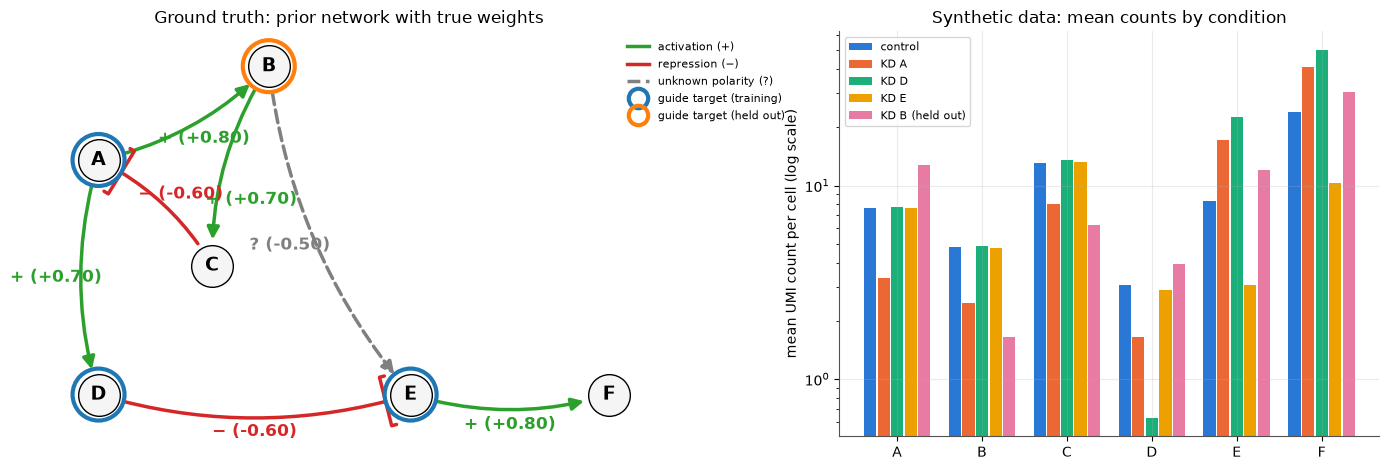

fraction of zero counts: 0.06


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
plot_network(
    GENES,
    EDGES,
    TRAIN_TARGETS,
    HELDOUT_TARGET,
    weights=TRUE["W"],
    ax=axes[0],
    title="Ground truth: prior network with true weights",
)
mean_counts = {
    c: data["counts"][CONDITION == c].mean(0)
    for c in ["control", *[f"KD {t}" for t in TRAIN_TARGETS]]
}
mean_counts[f"KD {HELDOUT_TARGET} (held out)"] = heldout_data["counts"].mean(0)
width = 0.16
for j, (cond, m) in enumerate(mean_counts.items()):
    axes[1].bar(np.arange(G) + (j - 2) * width, m.numpy(), width * 0.9, label=cond, color=SERIES[j])
axes[1].set_xticks(range(G), GENES)
axes[1].set_yscale("log")
axes[1].set_ylabel("mean UMI count per cell (log scale)")
axes[1].set_title("Synthetic data: mean counts by condition")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"fraction of zero counts: {(data['counts'] == 0).double().mean():.2f}")

In [7]:
assert spectral_radius(TRUE["W"]) < 1
# the solver agrees with simply iterating the equations until they settle
x = torch.randn(5, G)
z_iter = torch.zeros_like(x)
for _ in range(500):
    z_iter = x + z_iter @ TRUE["W"].T
assert torch.allclose(steady_state(TRUE["W"], x), z_iter, atol=1e-6)
# every cell carries at most one guide, and nobody in training carries the held-out guide
assert (data["guides"].sum(-1) <= 1).all()
assert (data["guides"][:, GUIDE_TARGETS.index(HELDOUT_TARGET)] == 0).all()
assert ((TRUE["W"] != 0).double() == mask).all()
assert torch.all(TRUE["W"][sign == 1] > 0) and torch.all(TRUE["W"][sign == -1] < 0)
# each training knockdown visibly lowers its own target, close to the analytic effect
logexpr = torch.log((data["counts"] + 0.5) / data["size_factors"][:, None])
ctrl = data["guides"].sum(-1) == 0
for t in TRAIN_TARGETS:
    k = GUIDE_TARGETS.index(t)
    kd = data["guides"][:, k] == 1
    shift = logexpr[kd, IDX[t]].mean() - logexpr[ctrl, IDX[t]].mean()
    expected = true_effect(TRUE["W"], TRUE["s"][k], IDX[t])[IDX[t]]
    assert shift < 0 and expected < 0, (t, shift, expected)
print("simulation checks passed")

simulation checks passed


## 4. The ChiRho model: where the network goes

The model is an ordinary Pyro program; ChiRho adds the causal operations (`do`, counterfactual
worlds) on top. The regulatory network enters in exactly two places:

1. **Structure → which weights exist.** Only edges in the prior network get a weight; every other
   entry of `W` is a hard zero (via `mask`).
2. **Polarity → the sign of each weight.** Activating edges are sampled from a positive
   distribution, repressing edges from a negative one, unknown edges from a symmetric one.

The CRISPR knockdown enters as **guide variables** `guide_A`, `guide_D`, … — one observed 0/1 sample
site per guide per cell. Because they are sample sites, ChiRho can intervene on them:
`do(actions={"guide_B": 1.0})` means *"give every cell a guide against B"*. The knockdown shift is
applied *inside* the gene's equation before the steady-state solve, so its effect travels through
the whole network — including around the feedback loop and back onto the target itself.

> Why not `do()` directly on a gene? ChiRho does support soft interventions on a value
> (e.g. `do(actions={"x": lambda x: x - 1.5})`), but shifting a gene's value *after* the joint
> steady-state solve would not propagate to the genes it regulates. Intervening on the guide —
> which is what the experimenter actually controls — gives the right semantics.

Knockdown strengths `s_k` are learned, one per guide, from a **shared population** of guide
strengths (`μ_s`, `τ_s`). A guide with no training cells (here, the one against `B`) therefore
gets its strength from that population — which is how we can predict a knockdown never observed.

`hard=True` switches to a hard knockdown at query time: the target is pinned at its no-guide level
minus `s_k` and its incoming edges are cut, so its regulators (and the feedback loop) no longer act on it. `fixed_strength` replaces the learned
strengths with a constant, used in Section 9.

In [8]:
SIGMA_W = 1.0
POS_EDGES = torch.nonzero((mask == 1) & (sign == 1), as_tuple=True)
NEG_EDGES = torch.nonzero((mask == 1) & (sign == -1), as_tuple=True)
UNK_EDGES = torch.nonzero((mask == 1) & (sign == 0), as_tuple=True)
TARGET_ONEHOT = torch.nn.functional.one_hot(TARGET_IDX, G).double()  # [K, G]


def grn_model(guides, size_factors, counts=None, hard=False, fixed_strength=None):
    """Steady-state, network-structured model of CRISPR scRNA-seq counts.

    guides: [N, K] 0/1 guide assignment; size_factors: [N]; counts: [N, G] or None.
    """
    n_cells = guides.shape[0]

    # --- prior network: structure (mask) + polarity (sign-constrained priors) ---
    w_pos = pyro.sample("w_pos", dist.HalfNormal(SIGMA_W).expand([len(POS_EDGES[0])]).to_event(1))
    w_neg = pyro.sample("w_neg", dist.HalfNormal(SIGMA_W).expand([len(NEG_EDGES[0])]).to_event(1))
    w_unk = pyro.sample("w_unk", dist.Normal(0.0, SIGMA_W).expand([len(UNK_EDGES[0])]).to_event(1))
    W = torch.zeros(*w_pos.shape[:-1], G, G)  # leading dims: posterior/sample batches, if any
    W[..., POS_EDGES[0], POS_EDGES[1]] = w_pos
    W[..., NEG_EDGES[0], NEG_EDGES[1]] = -w_neg
    W[..., UNK_EDGES[0], UNK_EDGES[1]] = w_unk
    W = pyro.deterministic("W", W, event_dim=2)  # absent edges stay exactly 0

    # --- gene baselines and cell-to-cell noise scale ---
    b = pyro.sample("b", dist.Normal(1.0, 2.0).expand([G]).to_event(1))
    sigma_e = pyro.sample("sigma_e", dist.HalfNormal(0.5))

    # --- knockdown strength per guide, from a shared population of guides ---
    mu_s = pyro.sample("mu_s", dist.Normal(math.log(1.2), 0.5))
    tau_s = pyro.sample("tau_s", dist.HalfNormal(0.3))
    if fixed_strength is None:
        s = pyro.sample("s", dist.LogNormal(mu_s, tau_s).expand([K]).to_event(1))
    else:
        s = pyro.deterministic("s", torch.full((K,), float(fixed_strength)), event_dim=1)

    with pyro.plate("cells", n_cells, dim=-1):
        # guide sites: observed here, intervened on with do() later
        guide_vals = [
            pyro.sample(f"guide_{t}", dist.Bernoulli(0.25), obs=guides[:, k])
            for k, t in enumerate(GUIDE_TARGETS)
        ]
        guide_mat = torch.stack(torch.broadcast_tensors(*guide_vals), dim=-1)  # [..., N, K]

        e = pyro.sample("e", dist.Normal(0.0, sigma_e).expand([G]).to_event(1))
        inputs = knockdown_inputs(b, e, guide_mat, s, TARGET_IDX)  # b + e - knockdown shift
        if hard:
            # hard knockdown: pin the target at (its no-guide steady state − s_k) and cut its
            # incoming edges, so regulators and feedback can no longer act on it
            knocked = (guide_mat @ TARGET_ONEHOT).clamp(max=1.0)  # [..., N, G]
            z_no_guide = steady_state(W, b + e)
            shift = (b + e) - inputs
            inputs = (b + e) + knocked * (z_no_guide - (b + e)) - shift
            W_cell = W * (1.0 - knocked.unsqueeze(-1))  # zero the target's row
            z = torch.linalg.solve(torch.eye(G) - W_cell, inputs.unsqueeze(-1)).squeeze(-1)
        else:
            z = steady_state(W, inputs)
        z = pyro.deterministic("z", z, event_dim=1)
        pyro.sample(
            "counts",
            dist.Poisson(size_factors.unsqueeze(-1) * torch.exp(z)).to_event(1),
            obs=counts,
        )
    return z

### The probabilistic model as a graph

Rendered directly from the code with `pyro.render_model`. Solid grey nodes are observed (guides, counts); dashed
nodes are deterministic functions of their parents (`W`, `z`); the box is the plate over cells. Read top to bottom: the edge weights (`w_pos`, `w_neg`, `w_unk`) assemble into the
network matrix `W`; together with baselines `b`, per-cell noise `e`, the guides and their
strengths `s`, they determine the steady state `z`, which generates the observed `counts`.

| node | meaning |
|---|---|
| `w_pos`, `w_neg`, `w_unk` | weights of activating / repressing / unknown-polarity edges |
| `W` | network matrix (deterministic; zero where the prior has no edge) |
| `b` | baseline log-expression per gene |
| `sigma_e`, `e` | scale and value of cell-to-cell variability |
| `mu_s`, `tau_s` | typical guide strength and guide-to-guide spread |
| `s` | knockdown strength of each guide (log scale) |
| `guide_A`, `guide_D`, `guide_E`, `guide_B` | which guide a cell carries — the intervention handles |
| `z` | steady-state log-expression (deterministic) |
| `counts` | observed UMI counts |

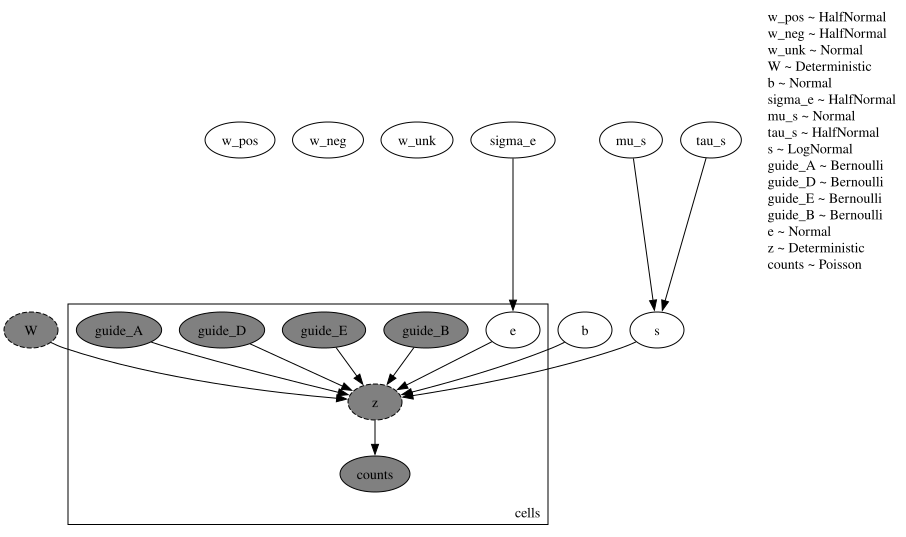

In [9]:
pyro.render_model(
    grn_model,
    model_args=(data["guides"][:20], data["size_factors"][:20], data["counts"][:20]),
    render_distributions=True,
    render_deterministic=True,
)

In [10]:
n_chk = 10
args_chk = (data["guides"][:n_chk], data["size_factors"][:n_chk])
Wp = Predictive(grn_model, num_samples=200, return_sites=["W"])(*args_chk)["W"].reshape(-1, G, G)
assert (Wp[:, mask == 0] == 0).all()  # structure: absent edges are exactly zero
assert (Wp[:, sign == 1] > 0).all() and (Wp[:, sign == -1] < 0).all()  # polarity respected
unknown = (mask == 1) & (sign == 0)
assert (Wp[:, unknown] > 0).any() and (
    Wp[:, unknown] < 0
).any()  # unknown edge can take either sign

# do() on a guide lowers its target, with all other randomness held fixed
no_guides = torch.zeros(n_chk, K)
with pyro.poutine.seed(rng_seed=1):
    z0 = do(grn_model, {"guide_A": torch.zeros(n_chk)})(no_guides, args_chk[1])
with pyro.poutine.seed(rng_seed=1):
    z1 = do(grn_model, {"guide_A": torch.ones(n_chk)})(no_guides, args_chk[1])
assert (z1[:, IDX["A"]] < z0[:, IDX["A"]]).all()
# hard and soft agree when no guide is active
with pyro.poutine.seed(rng_seed=1):
    z0_hard = grn_model(no_guides, args_chk[1], hard=True)
assert torch.allclose(z0, z0_hard)
print("model checks passed")

model checks passed


## 5. Fitting: stochastic variational inference

As in the SciPlex tutorial we use SVI with `Trace_ELBO`. The variational family ("guide") needs
one change from the tutorial's mean-field `AutoNormal`:

* **global parameters** (edge weights, baselines, strengths, …) get a joint Gaussian
  (`AutoMultivariateNormal`), so correlated quantities — e.g. edges around the feedback loop — are
  approximated together;
* **each cell's noise** `e_c` gets its own full-covariance Gaussian across the 6 genes.

With a fully factorised guide we found the edge weights were shrunk towards zero (e.g. `B → E`
estimated at −0.14 instead of −0.5): the factorised guide cannot represent how a cell's
noise in a regulator and in its target trade off, and the cheapest compromise is a weaker edge.
The data are the 3 200 training cells: control cells plus cells with guides against `A`, `D`, `E`.
No cell carries the guide against `B`.

Why include knockdown cells in training? With feedback loops, control cells alone only weakly pin
down edge weights (many networks produce similar steady-state covariation). Knockdowns are
interventions: they move one gene and reveal what responds downstream.

In [11]:
class CellNoiseGuide(PyroModule):
    """Variational posterior for the per-cell noise e_c: a full-covariance Gaussian per cell."""

    def __init__(self, n_cells, global_guide):
        """Initialise per-cell means at 0 and per-cell Cholesky factors at 0.1 I."""
        super().__init__()
        self.loc = PyroParam(torch.zeros(n_cells, G))
        self.scale_tril = PyroParam(
            0.1 * torch.eye(G).expand(n_cells, G, G).clone(), constraint=constraints.lower_cholesky
        )
        self.global_guide = [global_guide]  # list: keep it out of this module's parameters

    def forward(self, guides, *args, **kwargs):
        plates = self.global_guide[0].plates  # reuse the autoguide's "cells" plate
        with plates["cells"] if "cells" in plates else pyro.plate("cells", guides.shape[0], dim=-1):
            pyro.sample("e", dist.MultivariateNormal(self.loc, scale_tril=self.scale_tril))


def make_guide(n_cells):
    global_guide = AutoMultivariateNormal(
        pyro.poutine.block(grn_model, hide=["e"]), init_scale=0.05
    )
    guide = AutoGuideList(grn_model)
    guide.append(global_guide)
    guide.append(CellNoiseGuide(n_cells, global_guide))
    return guide


def fit(model_kwargs, num_steps=6000, lr=0.02, seed=0):
    """Fit grn_model with SVI; returns (guide, list of ELBO losses per cell)."""
    pyro.clear_param_store()
    pyro.set_rng_seed(seed)
    guide = make_guide(model_kwargs["guides"].shape[0])
    svi = SVI(
        grn_model,
        guide,
        pyro.optim.ClippedAdam({"lr": lr, "lrd": 0.1 ** (1 / num_steps)}),
        Trace_ELBO(),
    )
    n = model_kwargs["guides"].shape[0]
    losses = [svi.step(**model_kwargs) / n for _ in range(num_steps)]
    return guide, losses


train_kwargs = {
    "guides": data["guides"],
    "size_factors": data["size_factors"],
    "counts": data["counts"],
}
guide_soft, losses_soft = fit(train_kwargs)

GLOBAL_SITES = ["W", "s", "mu_s", "tau_s", "b", "sigma_e"]
NUM_POST = 500


def sample_posterior(guide, model_kwargs, num_samples=NUM_POST):
    """Posterior draws of the global sites, squeezed to [S, ...]."""
    kwargs = {**model_kwargs, "counts": None}
    out = Predictive(grn_model, guide=guide, num_samples=num_samples, return_sites=GLOBAL_SITES)(
        **kwargs
    )
    return {
        k: v.reshape(num_samples, *v.shape[-2:])
        if k == "W"
        else v.reshape(num_samples, -1).squeeze(-1)
        for k, v in out.items()
    }


posterior = sample_posterior(guide_soft, train_kwargs)
stable = spectral_radius(posterior["W"]) < 1
print(
    f"final loss per cell: {np.mean(losses_soft[-100:]):.3f}; stable posterior draws: {stable.double().mean():.3f}"
)

final loss per cell: 17.989; stable posterior draws: 1.000


In [12]:
assert all(math.isfinite(loss) for loss in losses_soft)
assert np.mean(losses_soft[-100:]) < np.mean(losses_soft[:100])
assert stable.double().mean() > 0.95
W_post = posterior["W"][stable]
W_err = (W_post.mean(0) - TRUE["W"])[mask == 1]
assert W_err.abs().max() <= 0.15, W_err  # every edge weight recovered to within 0.15
lo, hi = W_post.quantile(0.05, 0), W_post.quantile(0.95, 0)
covered = ((TRUE["W"] >= lo) & (TRUE["W"] <= hi))[mask == 1]  # reported, not asserted (see text)
assert (
    W_post[:, IDX["E"], IDX["B"]] < 0
).double().mean() > 0.9  # unknown polarity recovered: repressive
ks = [GUIDE_TARGETS.index(t) for t in TRAIN_TARGETS]
s_err = posterior["s"].mean(0)[ks] - TRUE["s"][ks]
assert s_err.abs().max() <= 0.3, s_err  # training-guide strengths recovered to within 0.3
print(f"edges covered by 90% intervals: {int(covered.sum())}/{int(mask.sum())}; fit checks passed")

edges covered by 90% intervals: 2/7; fit checks passed


## 6. Checks against the ground truth

Because the data are synthetic we can compare everything the model learned with the truth.

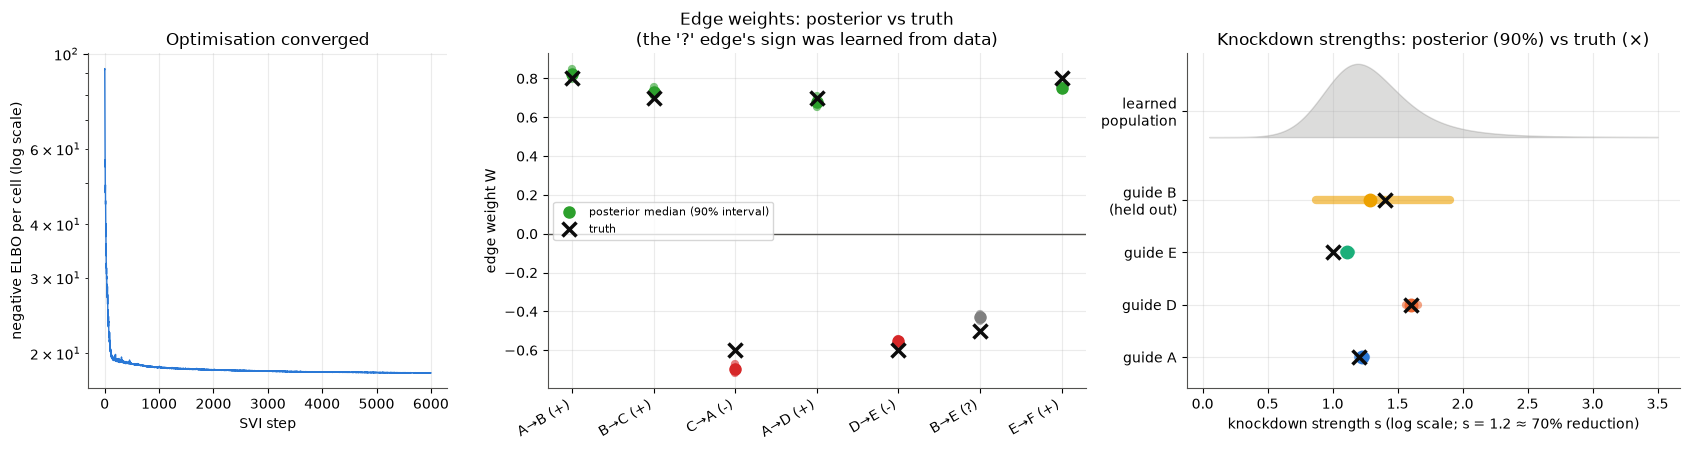

In [13]:
EDGE_LIST = [(p, c, pol) for p, c, pol in EDGES]
EDGE_NAMES = [f"{p}→{c} ({pol})" for p, c, pol in EDGE_LIST]
POL_COLOUR = {"+": "tab:green", "-": "tab:red", "?": "grey"}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [0.8, 1.2, 1.1]})
axes[0].plot(losses_soft, color=SERIES[0], lw=1)
axes[0].set_yscale("log")
axes[0].set(
    xlabel="SVI step", ylabel="negative ELBO per cell (log scale)", title="Optimisation converged"
)

ax = axes[1]
for j, (p, c, pol) in enumerate(EDGE_LIST):
    draws = W_post[:, IDX[c], IDX[p]]
    q05, q50, q95 = (draws.quantile(q) for q in (0.05, 0.5, 0.95))
    ax.plot([j, j], [q05, q95], color=POL_COLOUR[pol], lw=6, alpha=0.6, solid_capstyle="round")
    ax.plot(
        j,
        q50,
        "o",
        color=POL_COLOUR[pol],
        ms=8,
        label="posterior median (90% interval)" if j == 0 else None,
    )
    ax.plot(
        j,
        TRUE["W"][IDX[c], IDX[p]],
        "x",
        color=INK,
        ms=10,
        mew=2.5,
        label="truth" if j == 0 else None,
    )
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(range(len(EDGE_LIST)), EDGE_NAMES, rotation=30, ha="right")
ax.set(
    ylabel="edge weight W",
    title="Edge weights: posterior vs truth\n(the '?' edge's sign was learned from data)",
)
ax.legend(fontsize=8, loc="center left")

ax = axes[2]
grid = torch.linspace(0.05, 3.5, 300)
pop = (
    dist.LogNormal(posterior["mu_s"][:, None], posterior["tau_s"][:, None])
    .log_prob(grid)
    .exp()
    .mean(0)
)
ax.fill_between(grid, K + 0.2, K + 0.2 + 1.4 * pop / pop.max(), color=INK2, alpha=0.2)
for k, t in enumerate(GUIDE_TARGETS):
    draws = posterior["s"][:, k]
    ax.plot(
        [draws.quantile(0.05), draws.quantile(0.95)],
        [k, k],
        color=SERIES[k],
        lw=6,
        alpha=0.6,
        solid_capstyle="round",
    )
    ax.plot(draws.median(), k, "o", color=SERIES[k], ms=9)
    ax.plot(TRUE["s"][k], k, "x", color=INK, ms=10, mew=2.5)
ylabels = [f"guide {t}" + ("\n(held out)" if t == HELDOUT_TARGET else "") for t in GUIDE_TARGETS]
ax.set_yticks([*range(K), K + 0.7], [*ylabels, "learned\npopulation"])
ax.set_ylim(-0.6, K + 1.8)
ax.set(
    xlabel="knockdown strength s (log scale; s = 1.2 ≈ 70% reduction)",
    title="Knockdown strengths: posterior (90%) vs truth (×)",
)
plt.tight_layout()
plt.show()

**Reading these plots.**

* All edge weights are recovered, including the sign of the unknown `B → E` edge — the data
  say it is repressive, and the model did not need to be told.
* **The intervals are too narrow.** The 90% intervals cover only a few of the true values even
  though the point estimates are close. This is a known property of variational inference here:
  the guide treats each cell's noise as independent of the global parameters, so it
  under-states uncertainty. Treat the intervals as optimistic; for calibrated uncertainty use
  MCMC (NUTS) on a subsample of cells or a richer guide — a natural next step.
* **Identifiability of knockdown strength.** A guide shifts every gene by
  `s_k · (I − W)⁻¹[:, target]`. For a target with no regulators `s_k` is just its own drop; for
  `A`, which sits in the feedback loop, the observed drop mixes `s_A` with the loop's push-back,
  and the two are separated by control-cell covariation and the other knockdowns. The held-out
  guide `B` has no data, so its strength is simply the learned population — hence its wide interval.

### Posterior predictive check

Do *new* cells simulated from the fitted model look like the observed ones? We draw the global
parameters from the posterior but fresh cell-to-cell noise `e` from the model (not the fitted
noise of the training cells), and compare, per gene and condition, the mean and the variance of
the counts — the variance checks the over-dispersion.

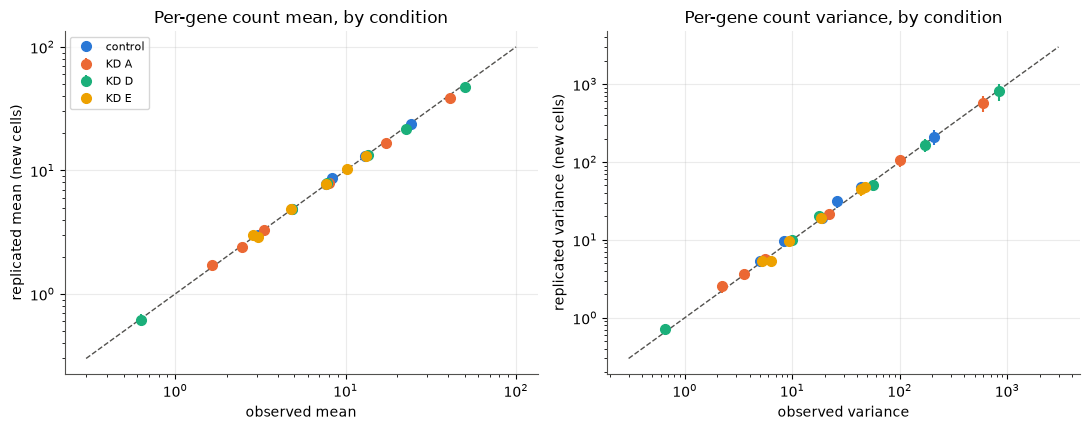

In [14]:
RAW_GLOBALS = ["w_pos", "w_neg", "w_unk", "b", "sigma_e", "mu_s", "tau_s", "s"]
n_ppc = 50
post_raw = Predictive(grn_model, guide=guide_soft, num_samples=n_ppc, return_sites=RAW_GLOBALS)(
    data["guides"], data["size_factors"]
)
post_raw = {k: v.reshape(n_ppc, -1).squeeze(-1) for k, v in post_raw.items()}
ppc = Predictive(grn_model, posterior_samples=post_raw, return_sites=["counts"])(
    data["guides"], data["size_factors"]
)
ppc = ppc["counts"].reshape(n_ppc, -1, G)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
conds = ["control", *[f"KD {t}" for t in TRAIN_TARGETS]]
for stat, ax in zip(["mean", "variance"], axes):
    for j, cond in enumerate(conds):
        sel = torch.as_tensor(CONDITION == cond)
        obs = data["counts"][sel].mean(0) if stat == "mean" else data["counts"][sel].var(0)
        rep = ppc[:, sel].mean(1) if stat == "mean" else ppc[:, sel].var(1)
        ax.errorbar(
            obs, rep.mean(0), yerr=2 * rep.std(0), fmt="o", color=SERIES[j], ms=7, label=cond
        )
    lim = [0.3, 3000 if stat == "variance" else 100]
    ax.plot(lim, lim, color=INK2, lw=1, ls="--")
    ax.set(
        xscale="log",
        yscale="log",
        xlabel=f"observed {stat}",
        ylabel=f"replicated {stat} (new cells)",
        title=f"Per-gene count {stat}, by condition",
    )
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Causal queries with `do()`: predicting a knockdown never seen in training

**Estimand.** The effect of knocking down gene `X` on gene `g` is the change in steady-state
log-expression (a log fold-change),

$$\text{effect}_g = \mathbb{E}\big[z_g \mid do(\text{guide}_X = 1)\big] - \mathbb{E}\big[z_g \mid do(\text{guide}_X = 0)\big],$$

averaged over the control cells. Following the SciPlex tutorial we compute it inside ChiRho's
`MultiWorldCounterfactual`: one call to the model produces, *for the same cells* (same noise
`e_c`), a world without the guide and a world with it. `gather(z, IndexSet(guide_B={k}))` picks
out world `k`.

**The held-out guide against `B`.** No training cell carries it, so its strength `s_B` comes from
the learned population of guide strengths. We show two views:

* **end-to-end prediction** — what we would actually predict for a new guide (includes the
  uncertainty about how strong that guide is);
* **per unit of knockdown** — the effect divided by `s_B`, i.e. `−(I − W)⁻¹[:, B]`. This isolates
  what the model learned about the *network* — how a perturbation of `B` propagates.

In [15]:
CTRL = torch.as_tensor(CONDITION == "control")


def knockdown_effect(guide, target, model_kwargs, num_samples=200, cells=CTRL, **query_kwargs):
    """Posterior draws [S, G] of the knockdown effect of `target`, via do() in a multi-world model.

    query_kwargs go to grn_model (e.g. hard=True); the guide supplies the posterior, including
    each training cell's own noise e_c, so both worlds share the same cells.
    """
    name = f"guide_{target}"

    def counterfactual_model(guides, size_factors):
        with MultiWorldCounterfactual(first_available_dim=-2):
            with do(actions={name: (torch.tensor(0.0), torch.tensor(1.0))}):
                z = grn_model(guides, size_factors, **query_kwargs)
            # world 0 = factual; worlds 1 and 2 = do(guide=0) and do(guide=1)
            z_off = gather(z, IndexSet(**{name: {1}}), event_dim=1)
            z_on = gather(z, IndexSet(**{name: {2}}), event_dim=1)
            effect = (z_on - z_off).reshape(-1, G)[cells].mean(0)
            pyro.deterministic("effect", effect, event_dim=1)
            pyro.deterministic("z_off", z_off.reshape(-1, G), event_dim=2)
            pyro.deterministic("z_on", z_on.reshape(-1, G), event_dim=2)

    out = Predictive(
        counterfactual_model,
        guide=guide,
        num_samples=num_samples,
        return_sites=["effect", "z_off", "z_on", "W"],
    )(model_kwargs["guides"], model_kwargs["size_factors"])
    keep = (
        spectral_radius(out["W"].reshape(num_samples, G, G)) < 1
    )  # only draws with a steady state
    return out["effect"].reshape(num_samples, G)[keep], out


effect_heldout_soft, cf_heldout = knockdown_effect(guide_soft, HELDOUT_TARGET, train_kwargs)

In [16]:
t, k = IDX[HELDOUT_TARGET], GUIDE_TARGETS.index(HELDOUT_TARGET)
analytic = true_effect(posterior["W"][stable], posterior["s"][stable][:, k : k + 1], t)  # [S, G]
# ChiRho's multi-world do() agrees with the closed-form effect s_k * (I - W)^-1[:, t]
assert torch.allclose(effect_heldout_soft.mean(0), analytic.mean(0), atol=0.05), (
    effect_heldout_soft.mean(0),
    analytic.mean(0),
)
truth = true_effect(TRUE["W"], TRUE["s"][k], t)
lo, hi = effect_heldout_soft.quantile(0.05, 0), effect_heldout_soft.quantile(0.95, 0)
covered_e2e = (truth >= lo) & (truth <= hi)
assert covered_e2e.double().mean() >= 0.8, (
    truth,
    lo,
    hi,
)  # end-to-end 90% intervals cover (nearly) all genes
print(
    "genes outside the end-to-end 90% interval:",
    [g for g, c in zip(GENES, covered_e2e) if not c] or "none",
)
per_unit_err = (analytic / posterior["s"][stable][:, k : k + 1]).mean(0) - truth / TRUE["s"][k]
assert per_unit_err.abs().max() <= 0.15, per_unit_err  # network propagation learned accurately
print("causal query checks passed")

genes outside the end-to-end 90% interval: ['F']
causal query checks passed


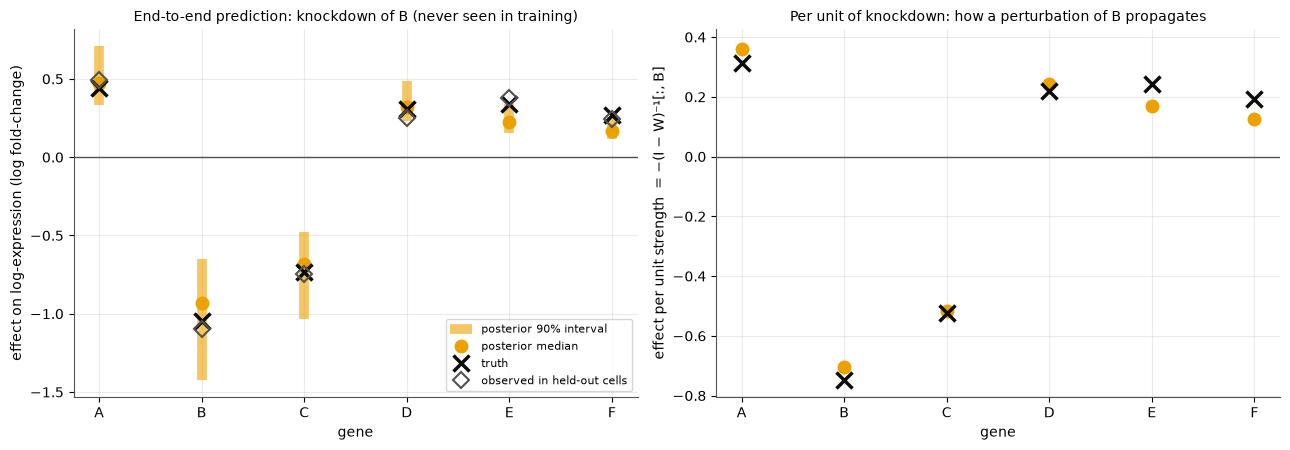

In [17]:
def empirical_shift(kd, ctrl_counts, ctrl_sf):
    """Observed log fold-change of size-normalised mean expression (knockdown cells vs control)."""
    return torch.log((kd["counts"] / kd["size_factors"][:, None]).mean(0)) - torch.log(
        (ctrl_counts / ctrl_sf[:, None]).mean(0)
    )


emp_heldout = empirical_shift(heldout_data, data["counts"][CTRL], data["size_factors"][CTRL])
per_unit = analytic / posterior["s"][stable][:, k : k + 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharex=True)
x = np.arange(G)
for ax, draws, tru, ttl, ylab in [
    (
        axes[0],
        effect_heldout_soft,
        truth,
        f"End-to-end prediction: knockdown of {HELDOUT_TARGET} (never seen in training)",
        "effect on log-expression (log fold-change)",
    ),
    (
        axes[1],
        per_unit,
        truth / TRUE["s"][k],
        f"Per unit of knockdown: how a perturbation of {HELDOUT_TARGET} propagates",
        "effect per unit strength  = −(I − W)⁻¹[:, B]",
    ),
]:
    q05, q50, q95 = (draws.quantile(q, 0) for q in (0.05, 0.5, 0.95))
    ax.vlines(x, q05, q95, color=SERIES[3], lw=7, alpha=0.6, label="posterior 90% interval")
    ax.plot(x, q50, "o", color=SERIES[3], ms=9, label="posterior median")
    ax.plot(x, tru, "x", color=INK, ms=11, mew=2.5, label="truth")
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xticks(x, GENES)
    ax.set(xlabel="gene", ylabel=ylab, title=ttl)
axes[0].plot(
    x, emp_heldout, "D", mfc="none", mec=INK2, ms=8, mew=1.5, label="observed in held-out cells"
)
axes[0].legend(fontsize=8)
for ax in axes:
    ax.title.set_fontsize(10)
plt.tight_layout()
plt.show()

**Reading this.** Knocking down `B` lowers `B` and `C` (its target), and *raises* `A` — the
feedback loop at work: less `B` → less `C` → less repression of `A`; `D` follows `A`. `E` rises
because the unknown-polarity edge `B → E` turned out repressive (outweighing the extra repression
from `D`), and `F` follows `E`. The model predicts all of
this for a guide it has never seen, because the knockdown propagates through the learned network.
The left panel's intervals are wide mostly because the guide's strength is unknown (drawn from the
population of guides); the right panel shows the network part alone is learned accurately (its
intervals are too narrow to see — the variational approximation is overconfident, see Section 6;
the largest misses, `E` and `F`, come from the slightly under-estimated `B → E` and `E → F` edges).

### Same-cell counterfactuals

The multi-world model also answers a per-cell question: *for this particular cell, what would its
expression have been with the guide against `B`?* Each arrow goes from a control cell's
expression without the guide to the same cell's counterfactual expression with it (posterior mean).

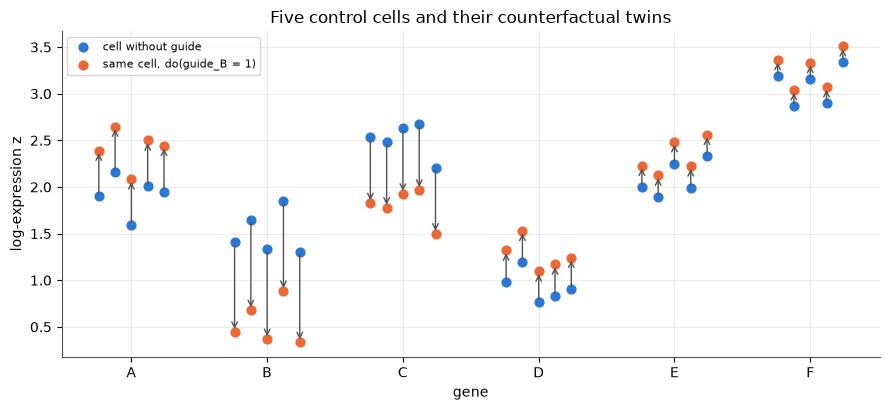

In [18]:
z_off = cf_heldout["z_off"].reshape(-1, data["guides"].shape[0], G).mean(0)[CTRL][:5]
z_on = cf_heldout["z_on"].reshape(-1, data["guides"].shape[0], G).mean(0)[CTRL][:5]
fig, ax = plt.subplots(figsize=(9, 4.2))
for c in range(z_off.shape[0]):
    xs = x + (c - 2) * 0.12
    ax.scatter(
        xs,
        z_off[c],
        color=SERIES[0],
        s=40,
        zorder=3,
        label="cell without guide" if c == 0 else None,
    )
    ax.scatter(
        xs,
        z_on[c],
        color=SERIES[1],
        s=40,
        zorder=3,
        label=f"same cell, do(guide_{HELDOUT_TARGET} = 1)" if c == 0 else None,
    )
    for j in range(G):
        ax.annotate(
            "",
            xy=(xs[j], z_on[c, j]),
            xytext=(xs[j], z_off[c, j]),
            arrowprops={"arrowstyle": "->", "color": INK2, "lw": 1},
        )
ax.set_xticks(x, GENES)
ax.set(
    xlabel="gene",
    ylabel="log-expression z",
    title="Five control cells and their counterfactual twins",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Soft vs hard knockdown: the feedback loop buffers CRISPRi

A **hard** intervention (`do` in the textbook sense) pins the target and cuts it off from its
regulators. A **soft** knockdown — closer to CRISPRi — pushes the target down by `s_k` but leaves
its regulation intact. The difference matters when the target sits in a feedback loop.

Here we knock down `A` both ways, using the *same fitted model* (no refit — only the intervention
changes, via `grn_model(..., hard=True)`). With the negative loop `A → B → C ⊣ A`, lowering `A`
lowers `C`, which relieves `C`'s repression of `A` and partly restores it. The hard knockdown
pins `A` at its no-guide level minus `s_A` and cuts its regulators, so there is no push-back and
`A` drops by the full `s_A`.

In [19]:
effect_A_soft, _ = knockdown_effect(guide_soft, "A", train_kwargs)
effect_A_hard, _ = knockdown_effect(
    guide_soft, "A", train_kwargs, hard=True
)  # same posterior, hard do()

In [20]:
a, kA = IDX["A"], GUIDE_TARGETS.index("A")
# in the true system, soft knockdown of A is buffered by feedback; hard is not
W_hard_true = TRUE["W"].clone()
W_hard_true[a] = 0.0
soft_true = true_effect(TRUE["W"], TRUE["s"][kA], a)
hard_true = true_effect(W_hard_true, TRUE["s"][kA], a)
assert soft_true[a].abs() < hard_true[a].abs()
# the fitted model reproduces the buffering
assert effect_A_soft[:, a].mean().abs() < effect_A_hard[:, a].mean().abs()
assert torch.allclose(
    effect_A_hard[:, a].mean(), -posterior["s"][:, kA].mean(), atol=0.05
)  # hard: drop = s_A
print("soft vs hard checks passed")

soft vs hard checks passed


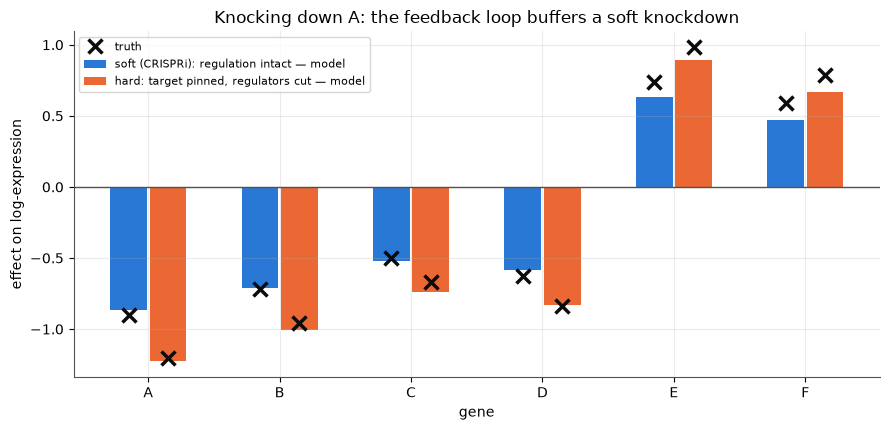

drop in A — soft: -0.86, hard: -1.23


In [21]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for j, (draws, tru, lbl) in enumerate(
    [
        (effect_A_soft, soft_true, "soft (CRISPRi): regulation intact"),
        (effect_A_hard, hard_true, "hard: target pinned, regulators cut"),
    ]
):
    xs = x + (j - 0.5) * 0.3
    ax.bar(xs, draws.mean(0), 0.28, color=SERIES[j], label=f"{lbl} — model")
    ax.plot(xs, tru, "x", color=INK, ms=10, mew=2.5, label="truth" if j == 0 else None)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(x, GENES)
ax.set(
    xlabel="gene",
    ylabel="effect on log-expression",
    title="Knocking down A: the feedback loop buffers a soft knockdown",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"drop in A — soft: {effect_A_soft[:, a].mean():.2f}, hard: {effect_A_hard[:, a].mean():.2f}")

## 9. What if we *assume* the knockdown strength?

A common shortcut is to treat a knockdown as a knockout, i.e. fix the strength instead of learning
it. We refit the same model with every guide's strength fixed at `log(100) ≈ 4.6` ("99% knockdown")
and compare all edge weights with the model that learns the strengths.

Intuition: the model is told each guide pushes its target down far harder than it really does, yet
the targets and their downstream genes moved only modestly. It has to explain that gap with the
network itself — for example by making feedback strong enough to cancel most of the push, or by
weakening the edges out of the knocked-down genes. Either way the network it learns is wrong.

In [22]:
FULL_KO = math.log(100.0)  # "99% knockdown"
guide_fixed, losses_fixed = fit({**train_kwargs, "fixed_strength": FULL_KO})
posterior_fixed = sample_posterior(guide_fixed, {**train_kwargs, "fixed_strength": FULL_KO})

In [23]:
err_learned = (posterior["W"].mean(0) - TRUE["W"])[mask == 1].abs()
err_fixed = (posterior_fixed["W"].mean(0) - TRUE["W"])[mask == 1].abs()
stable_fixed = (spectral_radius(posterior_fixed["W"]) < 1).double().mean()
assert err_fixed.mean() > 3 * err_learned.mean(), (
    err_fixed,
    err_learned,
)  # assumed strength distorts the network
assert np.mean(losses_fixed[-100:]) > np.mean(losses_soft[-100:])  # ... and fits the data worse
print(
    f"mean |edge error| — learned strength: {err_learned.mean():.2f}, fixed strength: {err_fixed.mean():.2f}"
)
print(f"fraction of fixed-strength posterior draws with a stable steady state: {stable_fixed:.2f}")
print("sensitivity checks passed")

mean |edge error| — learned strength: 0.05, fixed strength: 1.23
fraction of fixed-strength posterior draws with a stable steady state: 0.00
sensitivity checks passed


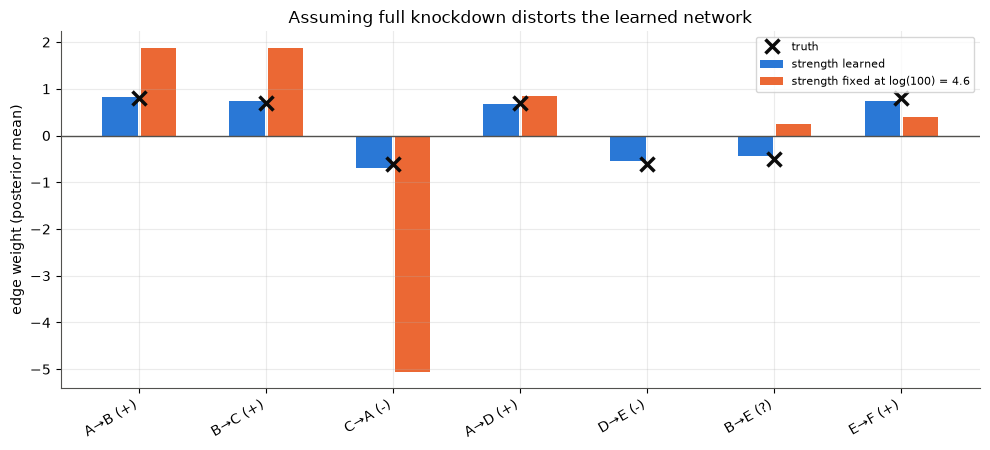

final loss per cell — learned: 17.989, fixed: 19.976


In [24]:
fig, ax = plt.subplots(figsize=(10, 4.6))
xe = np.arange(len(EDGE_LIST))
for j, (post, lbl) in enumerate(
    [
        (posterior, "strength learned"),
        (posterior_fixed, f"strength fixed at log(100) = {FULL_KO:.1f}"),
    ]
):
    vals = [post["W"][:, IDX[c], IDX[p]].mean() for p, c, _ in EDGE_LIST]
    ax.bar(xe + (j - 0.5) * 0.3, vals, 0.28, color=SERIES[j], label=lbl)
ax.plot(
    xe,
    [TRUE["W"][IDX[c], IDX[p]] for p, c, _ in EDGE_LIST],
    "x",
    color=INK,
    ms=10,
    mew=2.5,
    label="truth",
)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(xe, EDGE_NAMES, rotation=30, ha="right")
ax.set(
    ylabel="edge weight (posterior mean)",
    title="Assuming full knockdown distorts the learned network",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(
    f"final loss per cell — learned: {np.mean(losses_soft[-100:]):.3f}, fixed: {np.mean(losses_fixed[-100:]):.3f}"
)

**Reading this.** With the strength forced to "99%", the model inflates the feedback loop
(`C ⊣ A` becomes several times stronger than the truth) so that feedback can cancel most of the
assumed push, distorts the edges downstream of the guides, and gets the sign of the
unknown edge `B → E` wrong. The resulting network has no stable steady state (see the printed
fraction above), and it fits the data worse. Learning the strengths, with a shared prior across
guides, avoids this.